366
StartDatetime
2021-09-30     579.19
2021-10-01    2467.59
2021-10-02    2087.75
Freq: D, Name: Demand, dtype: float64
StartDatetime
2022-09-28    3673.44
2022-09-29    4170.49
2022-09-30    3426.76
Freq: D, Name: Demand, dtype: float64


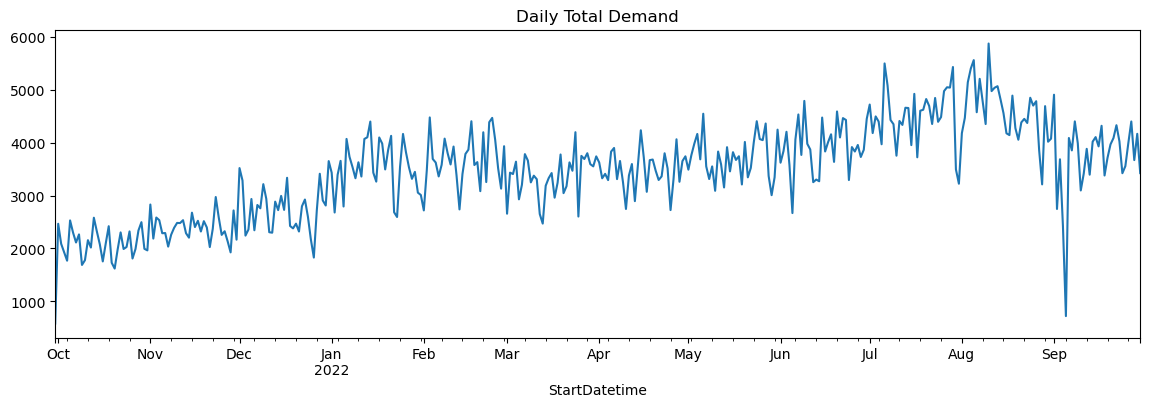

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/cleaned_data.csv", parse_dates=["StartDatetime"])
daily = df.set_index("StartDatetime")["Demand"].resample("D").sum()

print(len(daily))
print(daily.head(3)); print(daily.tail(3))   # check first/last day are not partial
daily.plot(figsize=(14, 4), title="Daily Total Demand"); plt.show()

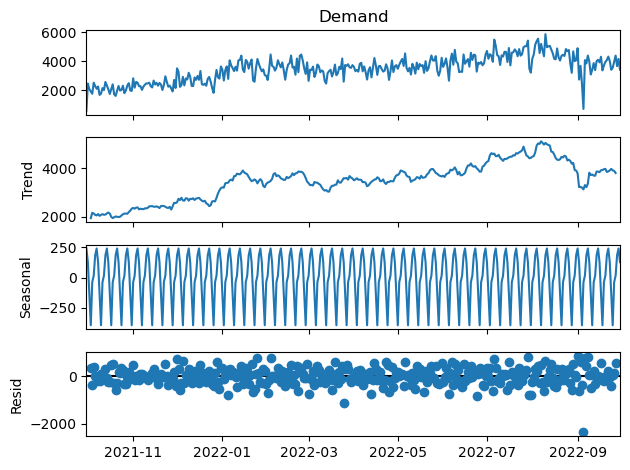

In [2]:
from statsmodels.tsa.seasonal import seasonal_decompose

res = seasonal_decompose(daily, model="additive", period=7)
res.plot(); plt.show()

In [3]:
from statsmodels.tsa.stattools import adfuller

stat, p, *_ = adfuller(daily.dropna())
print("ADF stat:", round(stat, 3), "p-value:", round(p, 4))
print("Stationary" if p < 0.05 else "Not stationary")

# also check after differencing
p2 = adfuller(daily.diff().dropna())[1]
print("After diff p-value:", round(p2, 4))

ADF stat: -1.883 p-value: 0.3399
Not stationary
After diff p-value: 0.0


In [4]:
n_test = int(len(daily) * 0.2)
train, test = daily.iloc[:-n_test], daily.iloc[-n_test:]
print(len(train), len(test))

293 73


In [5]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

def score(name, actual, pred):
    return {"Model": name,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred))}

results, preds = [], {}

# Moving Average (one-step-ahead: uses only past days)
for w in [3, 7, 14]:
    p = daily.rolling(w).mean().shift(1).loc[test.index]
    preds[f"MA-{w}"] = p
    results.append(score(f"Moving Average ({w}d)", test, p))

# Simple Exponential Smoothing
ses = SimpleExpSmoothing(train).fit()
preds["SES"] = ses.forecast(len(test))
results.append(score("Simple Exp Smoothing", test, preds["SES"]))

# Holt-Winters (trend + weekly seasonality)
hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=7).fit()
preds["Holt-Winters"] = hw.forecast(len(test))
results.append(score("Holt-Winters", test, preds["Holt-Winters"]))

results_df = pd.DataFrame(results).sort_values("RMSE").round(2)
results_df

,Model,MAE,RMSE
1,Moving Average (7d),498.87,690.70
2,Moving Average (14d),495.61,701.01
0,Moving Average (3d),529.56,720.15
3,Simple Exp Smoothing,586.79,808.08
4,Holt-Winters,813.22,1050.97


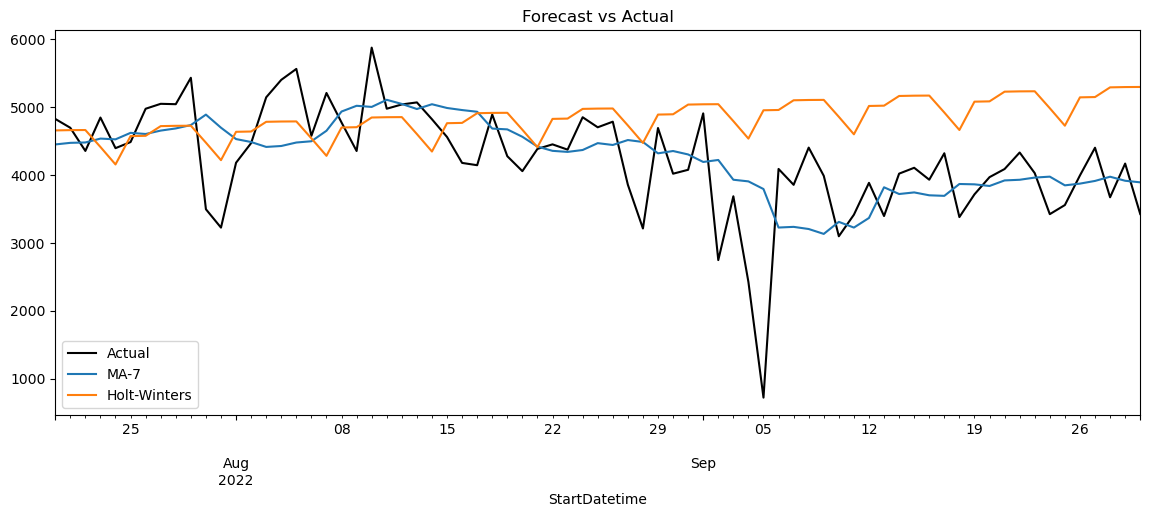

In [6]:
plt.figure(figsize=(14, 5))
test.plot(label="Actual", color="black")
preds["MA-7"].plot(label="MA-7")
preds["Holt-Winters"].plot(label="Holt-Winters")
plt.legend(); plt.title("Forecast vs Actual"); plt.show()

In [7]:
monthly = daily.resample("MS").sum()
change = monthly.pct_change().mul(100).round(1)
print(pd.DataFrame({"Demand": monthly.round(0), "Change%": change}))

import os
os.makedirs("../results", exist_ok=True)
results_df.to_csv("../results/timeseries_results.csv", index=False)

                 Demand  Change%
StartDatetime                   
2021-09-01        579.0      NaN
2021-10-01      64933.0  11111.1
2021-11-01      71742.0     10.5
2021-12-01      85158.0     18.7
2022-01-01     109689.0     28.8
2022-02-01     103220.0     -5.9
2022-03-01     104004.0      0.8
2022-04-01     104414.0      0.4
2022-05-01     115352.0     10.5
2022-06-01     117564.0      1.9
2022-07-01     139687.0     18.8
2022-08-01     143041.0      2.4
2022-09-01     111193.0    -22.3


In [8]:
import joblib, json, os
os.makedirs("../models", exist_ok=True)

daily_f = daily.asfreq("D")

# final models fitted on the full daily series (used for future forecasts)
ses_final = SimpleExpSmoothing(daily_f).fit()
hw_final = ExponentialSmoothing(daily_f, trend="add", seasonal="add",
                                seasonal_periods=7).fit()

joblib.dump(ses_final, "../models/ses_model.pkl")
joblib.dump(hw_final, "../models/holt_winters_model.pkl")

# Moving Average: nothing to train, so save the settings and the best scores
best_ma = results_df[results_df["Model"].str.contains("Moving")].iloc[0]
json.dump({"model": "Moving Average", "window": 7,
           "MAE": float(best_ma["MAE"]), "RMSE": float(best_ma["RMSE"])},
          open("../models/moving_average_config.json", "w"))
print("saved")

saved
